In [1]:
import os, sys, json, time, shutil, glob
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

REQUIRED = ["Nhanh_AB_scaled/common_eval.py", "week05_Khoa/feature_list.json", "cic_ids_2017_cleaned.parquet",
            "outputs/baseline/split_indices.npz", "tuan4_Trung/split_70_15_15_classweight.npz",
            "tuan4_Trung/scaler.joblib"]

BASE_DIR_OVERRIDE = ""   
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")

def find_base_dir():
    if BASE_DIR_OVERRIDE:
        return Path(BASE_DIR_OVERRIDE)
    if os.environ.get("AB_BASE"):
        return Path(os.environ["AB_BASE"])
    if not IN_COLAB:
        return Path(r"E:\Thuc tap")
    for root in ("/content/drive/MyDrive", "/content/drive/Shareddrives", "/content/drive/.shortcut-targets-by-id"):
        for depth in range(6):
            hits = glob.glob(os.path.join(root, *(["*"] * depth), "Nhanh_AB_scaled", "common_eval.py"))
            if hits:
                return Path(hits[0]).parent.parent
    raise FileNotFoundError("Không tìm thấy Nhanh_AB_scaled/common_eval.py trên Drive. Tải cả thư mục Nhanh_AB_scaled lên "
                            "Drive (cùng cấp với train_val_test_scaled, tuan4_Trung, ...) hoặc điền BASE_DIR_OVERRIDE.")

BASE_DIR = find_base_dir()
NAB_DIR = BASE_DIR / "Nhanh_AB_scaled"
os.environ["AB_BASE"] = str(BASE_DIR)
if str(NAB_DIR) not in sys.path:
    sys.path.insert(0, str(NAB_DIR))
missing = [f for f in REQUIRED if not (BASE_DIR / f).exists()]
if missing:
    raise FileNotFoundError(f"Thiếu file trong {BASE_DIR}:\n  " + "\n  ".join(missing))
import importlib, common_eval as L
importlib.reload(L)

SMOKE = int(os.environ.get("AB_SMOKE", 0)) 
USE_GPU = False   
BRANCH = "B"
OUT = L.out_dir(BRANCH, smoke=bool(SMOKE)); FIG = OUT / "figures"; FIG.mkdir(exist_ok=True)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)
print("Thư mục gốc  :", BASE_DIR)
print("Nhánh        :", L.BRANCH_NAME[BRANCH])
print("Kết quả lưu ở:", OUT)
print("Chế độ       :", f"CHẠY THỬ {SMOKE:,} dòng/tập" if SMOKE else "ĐẦY ĐỦ")
print("Phiên bản    :", L.versions())

Thư mục gốc  : E:\Thuc tap
Nhánh        : Nhánh B – 70/15/15 (đã scale)
Kết quả lưu ở: E:\Thuc tap\Nhanh_AB_scaled\outputs\B
Chế độ       : ĐẦY ĐỦ
Phiên bản    : {'python': '3.11.9', 'numpy': '2.4.4', 'pandas': '3.0.2', 'sklearn': '1.8.0', 'xgboost': '3.2.0', 'lightgbm': '4.7.0'}


## 1. Dữ liệu

In [2]:
data = L.load_branch(BRANCH, smoke=SMOKE)
print("Chia tập:", data["split"]); print("Nguồn  :", data["source"])
L.show(L.describe(data), "Kích thước các tập")
L.show(L.scaling_check(data), "Kiểm tra scale: train phải có |mean| ≈ 0 và std ≈ 1 (scaler fit trên train)", 5)

Chia tập: ngẫu nhiên 70/15/15, stratify, seed 42 (cùng dòng với mô hình đã khóa)
Nguồn  : tuan4_Trung/split_70_15_15_classweight.npz (scaler.joblib, fit trên train)

=== Kích thước các tập ===
       tập  số dòng  benign  attack  attack %                                                                                                                                                                                                                         loại tấn công
     train  1216280 1019490  196790     16.18 Botnet, DDoS, DoS GoldenEye, DoS Hulk, DoS Slowhttptest, DoS Slowloris, FTP-Patator, Heartbleed, Infiltration, Infiltration - Portscan, Portscan, SSH-Patator, Web Attack - Brute Force, Web Attack - SQL Injection, Web Attack - XSS
validation   260631  218462   42169     16.18 Botnet, DDoS, DoS GoldenEye, DoS Hulk, DoS Slowhttptest, DoS Slowloris, FTP-Patator, Heartbleed, Infiltration, Infiltration - Portscan, Portscan, SSH-Patator, Web Attack - Brute Force, Web Attack - SQL Injecti

## 2. Tham số chung (giống hệt Nhánh A)

In [3]:
L.show(L.params_table(), "THAM SỐ CHUNG cho cả hai nhánh (common_eval.PARAMS)", 4)
for k, v in L.PARAM_NOTES.items():
    print(f"- {k}: {v}")
print("\nNgưỡng: chọn trên validation – thấp nhất giữ FPR ≤ 1%, ≤ 0,1%, và 0,5.  Ngưỡng chính để so sánh:", L.RULE_VI[L.MAIN_RULE])
print("Chọn mô hình:", L.SELECT_RULE)


=== THAM SỐ CHUNG cho cả hai nhánh (common_eval.PARAMS) ===
                      xgboost random_forest           lightgbm
class_weight                –      balanced                  –
early_stopping_rounds      50             –                 50
eval_metric             aucpr             –                  –
is_unbalance                –             –               True
learning_rate             0.1             –                0.1
max_depth                   6             –                  –
max_features                –          sqrt                  –
metric                      –             –  average_precision
n_estimators             1000           100               1000
n_jobs                     -1            -1                 -1
num_leaves                  –             –                 31
random_state               42            42                 42
scale_pos_weight         auto             –                  –
tree_method              hist             –              

## 3. Huấn luyện – tái sử dụng mô hình 31/10 (cùng dữ liệu, cùng tham số)

In [4]:
REUSE_MODELS = True
REUSE_DIR = BASE_DIR / "Nhanh_A_B" / "outputs" / "A" / "models"

models, info = {}, []
for m in L.MODELS:
    mdl, how, tt, src_ver = None, "train mới", np.nan, None
    p = REUSE_DIR / f"binary_{m}.joblib"
    if REUSE_MODELS and not SMOKE and p.exists():
        try:
            b = L.load_bundle(p)
            diff = L.check_params(m, b["model"])
            if b["features"] == data["features"] and "split_70_15_15" in b["data_source"] and not diff:
                mdl, how, src_ver = b["model"], "tái sử dụng 31/10", b.get("versions")
            else:
                L.log(f"{m}: mô hình cũ không khớp ({diff or 'nguồn dữ liệu / cột'}) -> train lại")
        except Exception as e:
            L.log(f"{m}: không nạp được mô hình cũ ({type(e).__name__}: {e}) -> train lại")
    if mdl is None:
        t0 = time.time()
        mdl = L.fit_model(m, data["Xtr"], data["ytr"], data["Xva"], data["yva"], use_gpu=USE_GPU)
        tt = round(time.time() - t0, 1)
    models[m] = mdl
    info.append({"model": m, "nguồn": how, "train_time_s": tt, "n_trees": L.n_trees_used(mdl),
                 "infer_ms_per_1k": L.infer_ms_per_1k(mdl, data["Xte"])})
    L.log(f"{m}: {how}" + (f" (môi trường gốc: {src_ver})" if src_ver else f", train {tt}s"))
info = pd.DataFrame(info)
L.show(info.set_index("model"), "Huấn luyện / tái sử dụng")
cur = L.versions()
if (info["nguồn"] != "train mới").any():
    print("Môi trường hiện tại:", cur)

17:51:03 | xgboost: tái sử dụng 31/10 (môi trường gốc: {'python': '3.11.9', 'numpy': '2.4.4', 'pandas': '3.0.2', 'sklearn': '1.8.0', 'xgboost': '3.2.0', 'lightgbm': '4.7.0'})
17:51:04 | random_forest: tái sử dụng 31/10 (môi trường gốc: {'python': '3.11.9', 'numpy': '2.4.4', 'pandas': '3.0.2', 'sklearn': '1.8.0', 'xgboost': '3.2.0', 'lightgbm': '4.7.0'})
17:51:04 | lightgbm: tái sử dụng 31/10 (môi trường gốc: {'python': '3.11.9', 'numpy': '2.4.4', 'pandas': '3.0.2', 'sklearn': '1.8.0', 'xgboost': '3.2.0', 'lightgbm': '4.7.0'})

=== Huấn luyện / tái sử dụng ===
                           nguồn  train_time_s  n_trees  infer_ms_per_1k
model                                                                   
xgboost        tái sử dụng 31/10           NaN       96           0.3425
random_forest  tái sử dụng 31/10           NaN      100           2.9846
lightgbm       tái sử dụng 31/10           NaN       65           2.5131
Môi trường hiện tại: {'python': '3.11.9', 'numpy': '2.4.4', 'pandas':

## 4. Trực quan hóa quá trình huấn luyện

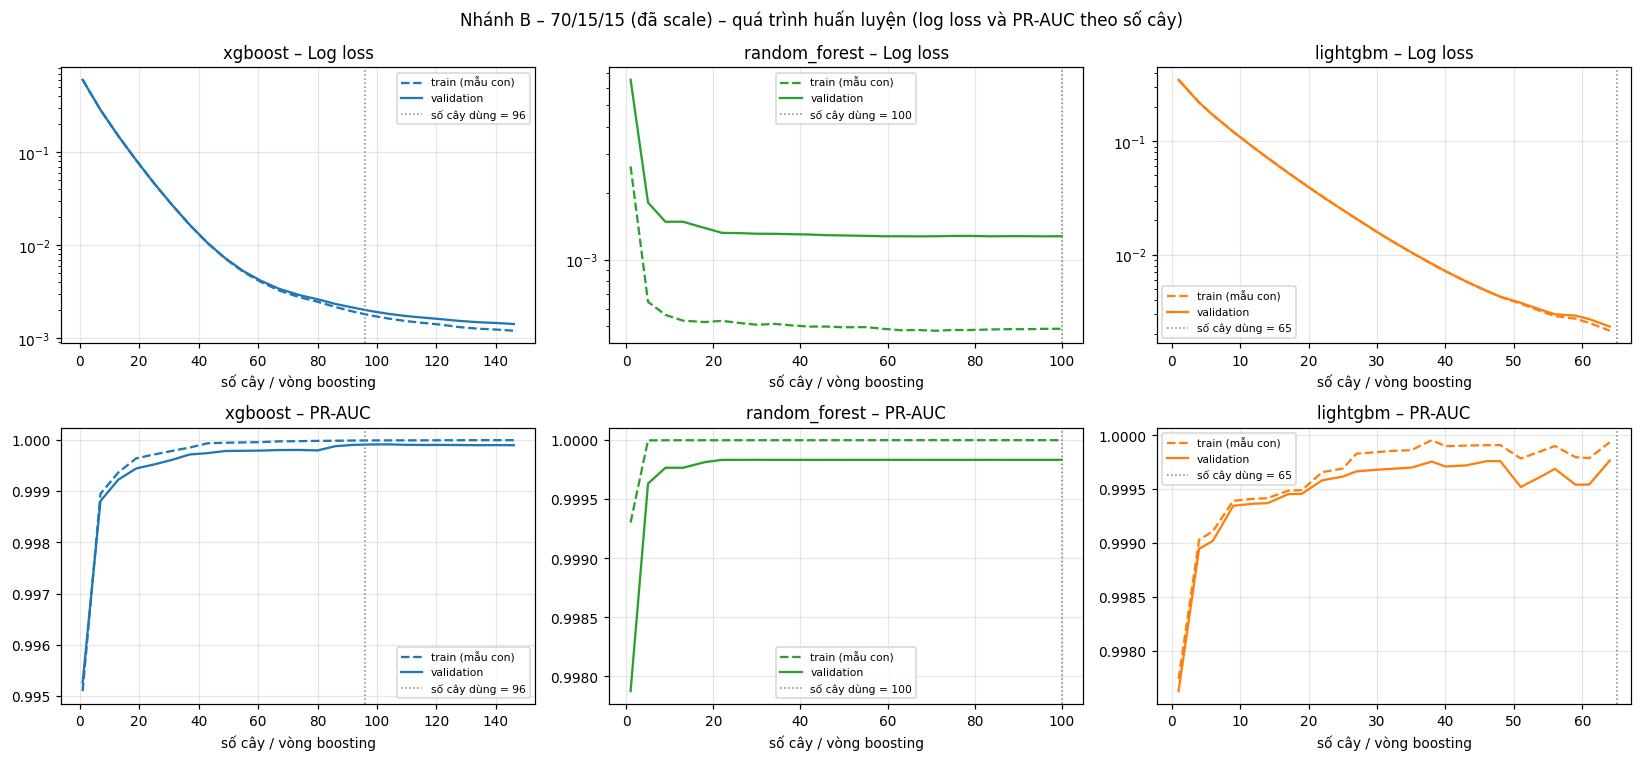

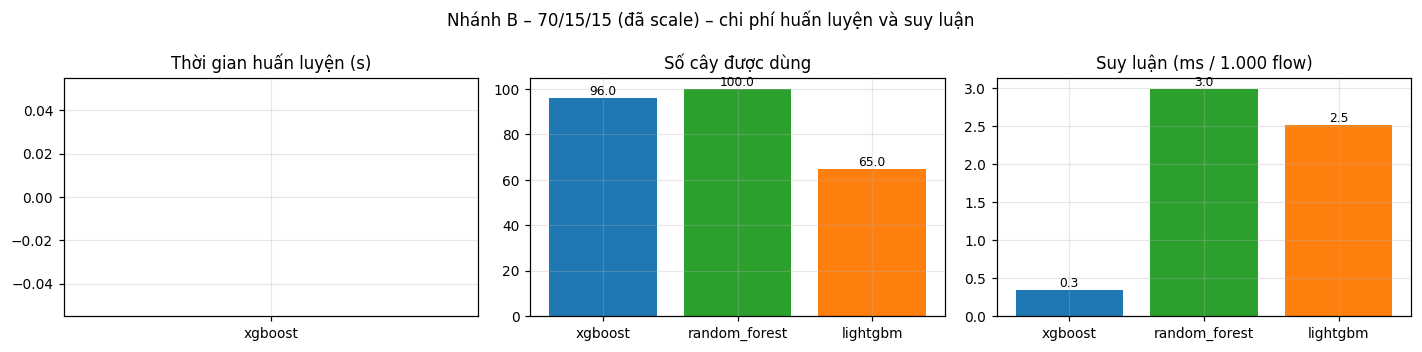


=== Cuối quá trình huấn luyện: train so với validation (khoảng cách lớn -> có dấu hiệu overfit) ===
               logloss | train (mẫu con)  logloss | validation  pr_auc | train (mẫu con)  pr_auc | validation  khoảng cách logloss (val − train)
model                                                                                                                                           
lightgbm                         0.00212               0.00231                   0.99993              0.99977                            0.00019
random_forest                    0.00049               0.00128                   1.00000              0.99983                            0.00079
xgboost                          0.00120               0.00142                   0.99999              0.99989                            0.00022


In [5]:
Xs_tr, ys_tr = L.train_subsample(data, n=20000 if SMOKE else 200000)
sets = {"train (mẫu con)": (Xs_tr, ys_tr), "validation": (data["Xva"], data["yva"])}
curves = pd.concat([L.learning_curve(m, models[m], sets) for m in L.MODELS], ignore_index=True)
curves.to_csv(OUT / "learning_curves.csv", index=False, float_format="%.6f")
L.plot_learning_curves(curves, info.set_index("model").n_trees.to_dict(),
                       f"{L.BRANCH_NAME[BRANCH]} – quá trình huấn luyện (log loss và PR-AUC theo số cây)",
                       FIG / "1_learning_curves.png"); plt.show()
L.plot_time(info, f"{L.BRANCH_NAME[BRANCH]} – chi phí huấn luyện và suy luận", FIG / "2_time.png"); plt.show()

last = curves.sort_values("n_trees").groupby(["model", "set"]).tail(1).pivot(index="model", columns="set", values=["logloss", "pr_auc"])
last.columns = [f"{a} | {b}" for a, b in last.columns]
last["khoảng cách logloss (val − train)"] = last["logloss | validation"] - last["logloss | train (mẫu con)"]
L.show(last, "Cuối quá trình huấn luyện: train so với validation (khoảng cách lớn -> có dấu hiệu overfit)", 5)

## 5. Bộ đánh giá chung
### 5.1. Ngưỡng (validation) và chỉ số

In [6]:
p_val = {m: models[m].predict_proba(data["Xva"])[:, 1] for m in L.MODELS}
p_test = {m: models[m].predict_proba(data["Xte"])[:, 1] for m in L.MODELS}
thr = {m: L.thresholds_from_val(data["yva"], p_val[m]) for m in L.MODELS}
val_rows = pd.DataFrame(sum([L.evaluate(m, data["yva"], p_val[m], thr[m], split="val") for m in L.MODELS], []))
test_rows = pd.DataFrame(sum([L.evaluate(m, data["yte"], p_test[m], thr[m], labels=data["mte"].Label) for m in L.MODELS], []))
val_rows.to_csv(OUT / "metrics_val.csv", index=False, float_format="%.6f")
test_rows.to_csv(OUT / "metrics_test.csv", index=False, float_format="%.6f")

print("\n=== Ngưỡng chọn trên validation ===")
print(pd.DataFrame(thr).T.map(lambda v: f"{v:.4g}").to_string())
cols = ["model", "rule", "threshold", "recall", "fpr", "precision", "f1", "fn", "fp", "pr_auc", "roc_auc"]
L.show(val_rows[val_rows.scope == "ALL"][cols].set_index(["model", "rule"]), "VALIDATION")
L.show(test_rows[test_rows.scope == "ALL"][cols].set_index(["model", "rule"]), "TEST")
gap = (val_rows[val_rows.scope == "ALL"].set_index(["model", "rule"])[["recall", "fpr"]]
       .join(test_rows[test_rows.scope == "ALL"].set_index(["model", "rule"])[["recall", "fpr"]], lsuffix=" val", rsuffix=" test"))
gap["recall giảm val→test"] = gap["recall val"] - gap["recall test"]
L.show(gap, "Validation so với test")


=== Ngưỡng chọn trên validation ===
                  fpr1%  fpr0.1%  0.5
xgboost         0.01166   0.1477  0.5
random_forest  0.002632  0.04597  0.5
lightgbm       0.005701   0.1467  0.5

=== VALIDATION ===
                       threshold  recall     fpr  precision      f1  fn    fp  pr_auc  roc_auc
model         rule                                                                            
xgboost       fpr1%       0.0117  0.9999  0.0099     0.9512  0.9749   4  2163  0.9999      1.0
              fpr0.1%     0.1477  0.9998  0.0010     0.9949  0.9973   9   218  0.9999      1.0
              0.5         0.5000  0.9997  0.0004     0.9981  0.9989  14    80  0.9999      1.0
random_forest fpr1%       0.0026  1.0000  0.0065     0.9676  0.9835   2  1412  0.9998      1.0
              fpr0.1%     0.0460  0.9999  0.0009     0.9953  0.9976   3   199  0.9998      1.0
              0.5         0.5000  0.9997  0.0003     0.9987  0.9992  14    55  0.9998      1.0
lightgbm      fpr1%       0.005

### 5.2. Biểu đồ đánh giá

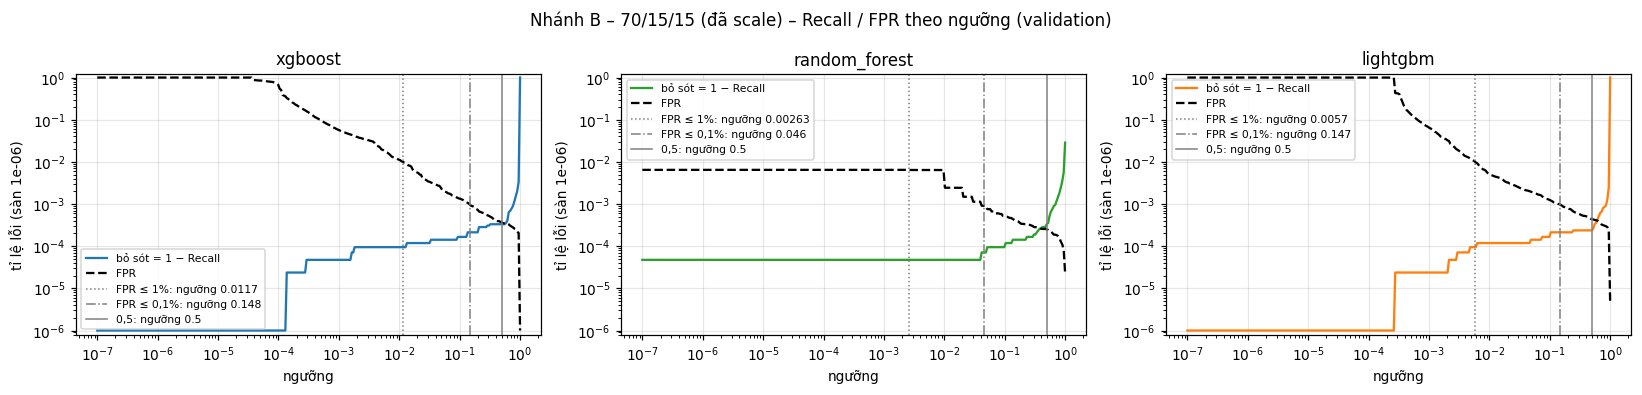

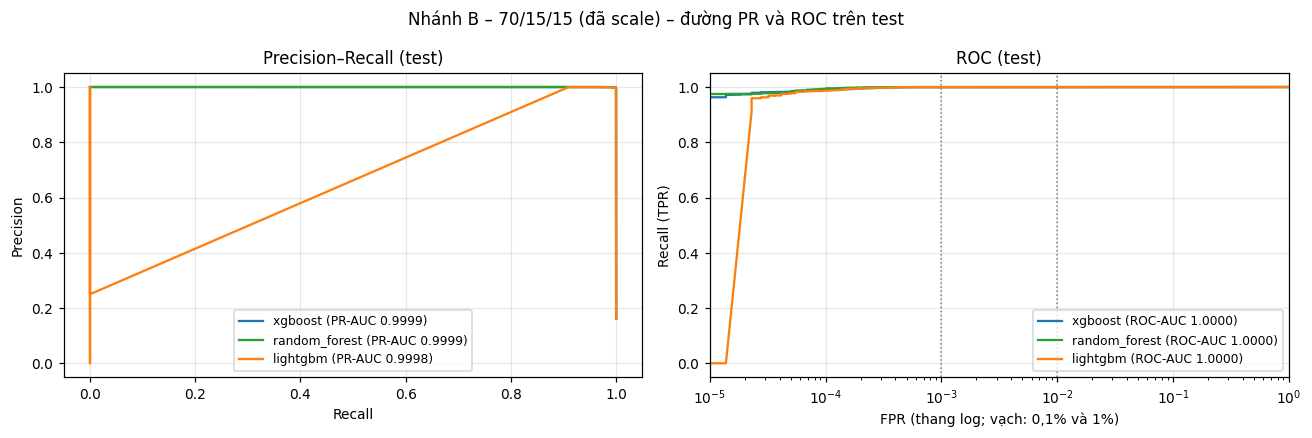

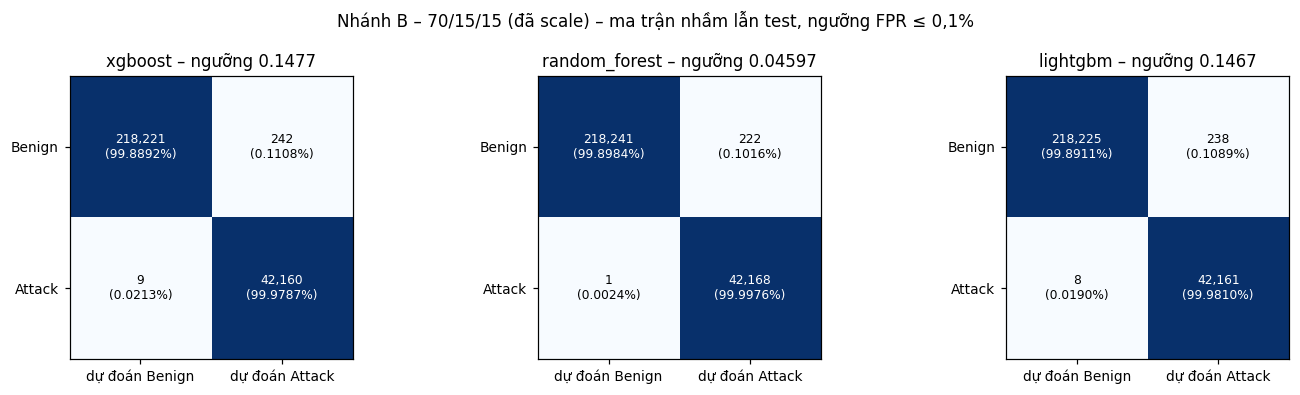

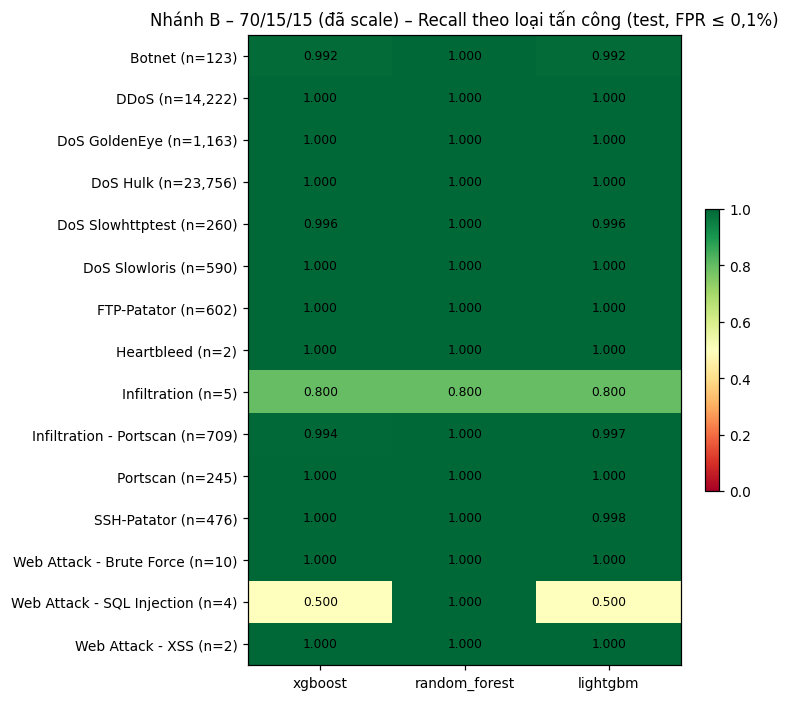

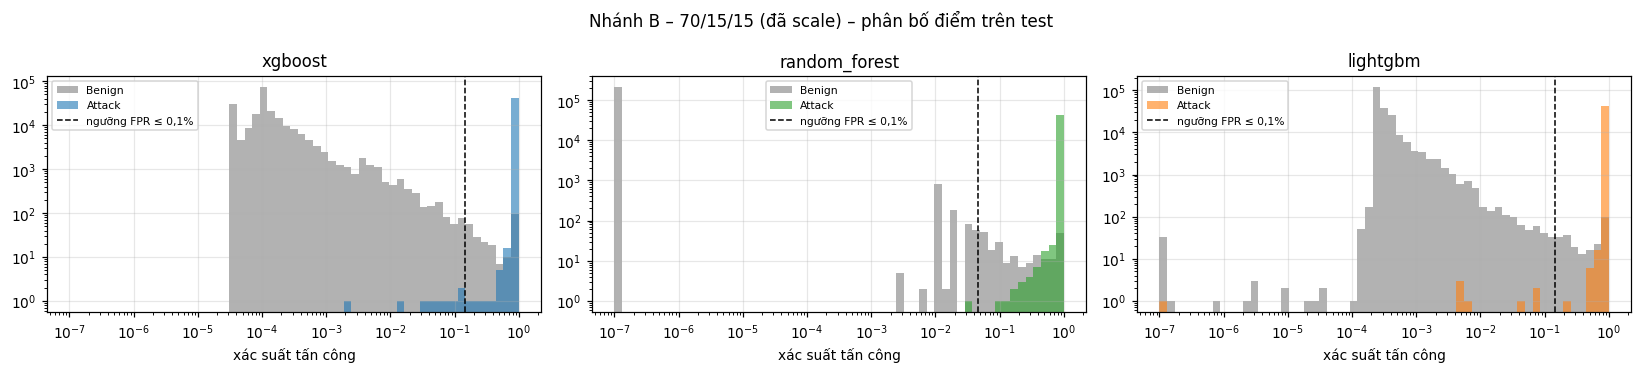

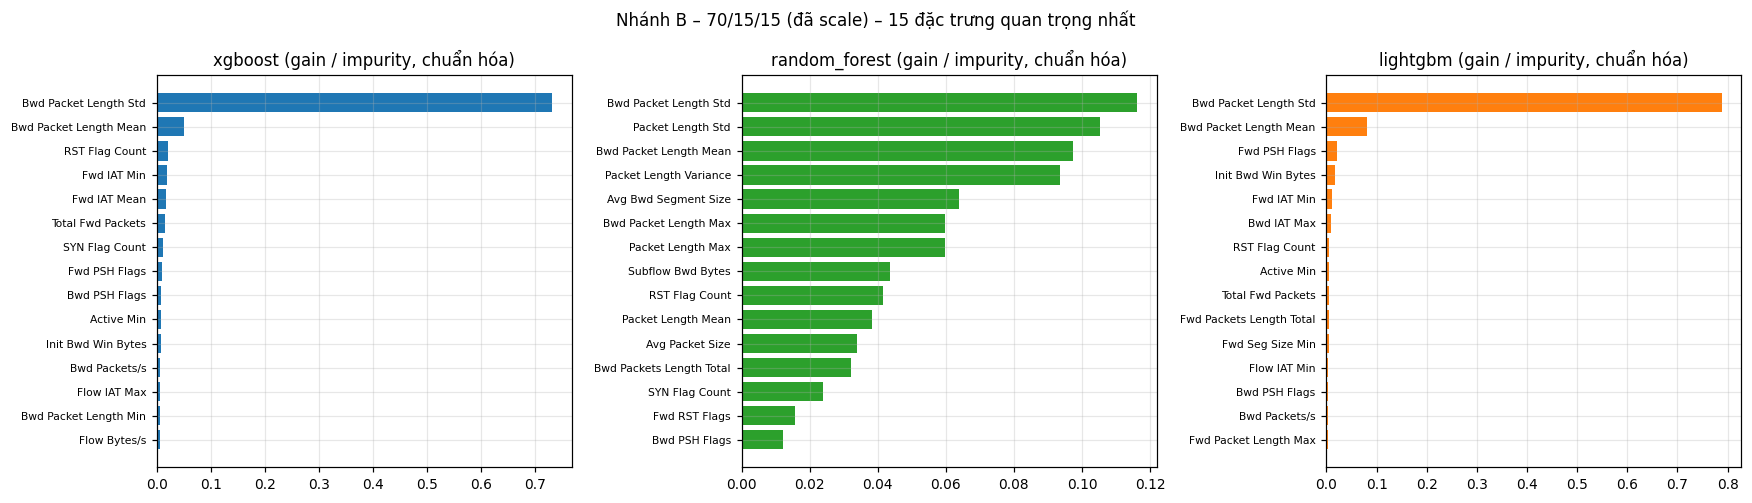

In [7]:
T = L.BRANCH_NAME[BRANCH]
L.plot_threshold_sweep(p_val, data["yva"], thr, f"{T} – Recall / FPR theo ngưỡng (validation)", FIG / "3_threshold_sweep.png"); plt.show()
L.plot_pr_roc(p_test, data["yte"], f"{T} – đường PR và ROC trên test", FIG / "4_pr_roc.png"); plt.show()
L.plot_confusions(test_rows, L.MAIN_RULE, T, FIG / "5_confusion.png"); plt.show()
L.plot_per_attack(test_rows, L.MAIN_RULE, T, FIG / "6_per_attack.png"); plt.show()
L.plot_score_hist(p_test, data["yte"], thr, T, FIG / "7_score_hist.png"); plt.show()
imp = L.plot_feature_importance(models, data["features"], T, path=FIG / "8_feature_importance.png"); plt.show()
imp.to_csv(OUT / "feature_importance.csv", float_format="%.6f")

## 6. So sánh 3 mô hình trong Nhánh B


=== Nhánh B – 70/15/15 (đã scale) – SO SÁNH 3 MÔ HÌNH TRÊN TEST ===
model                                 xgboost  random_forest    lightgbm
recall @fpr1%                         0.99998        1.00000     0.99991
recall @fpr0.1%                       0.99979        0.99998     0.99981
recall @0.5                           0.99964        0.99948     0.99979
FPR @fpr1%                            0.01020        0.00620     0.01013
FPR @fpr0.1%                          0.00111        0.00102     0.00109
FPR @0.5                              0.00049        0.00032     0.00058
FN @fpr1%                             1.00000        0.00000     4.00000
FN @fpr0.1%                           9.00000        1.00000     8.00000
FN @0.5                              15.00000       22.00000     9.00000
FP @fpr1%                          2228.00000     1355.00000  2212.00000
FP @fpr0.1%                         242.00000      222.00000   238.00000
FP @0.5                             107.00000       69.

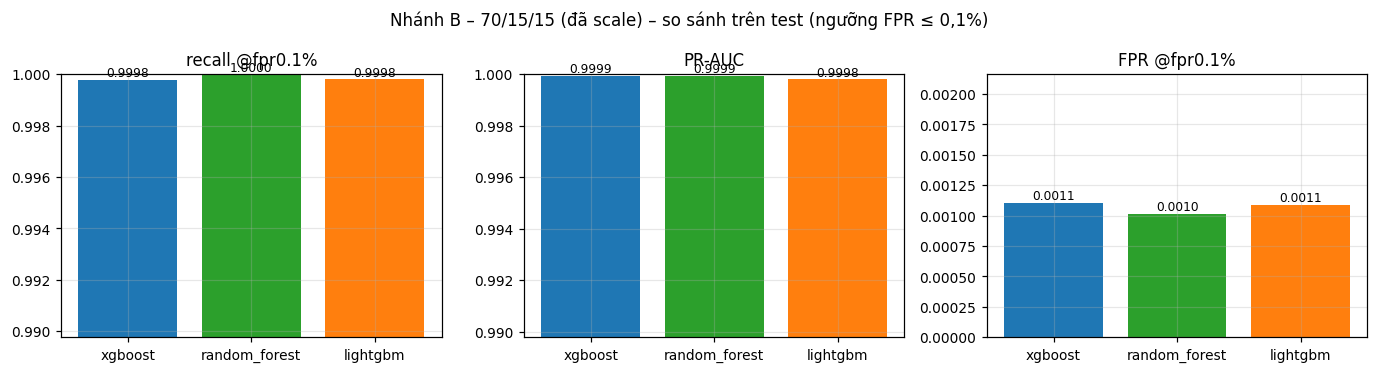


=== Recall theo loại tấn công (test, FPR ≤ 0,1%) ===
model                           n  lightgbm  random_forest  xgboost
scope                                                              
Botnet                        123    0.9919            1.0   0.9919
DDoS                        14222    1.0000            1.0   1.0000
DoS GoldenEye                1163    1.0000            1.0   1.0000
DoS Hulk                    23756    1.0000            1.0   1.0000
DoS Slowhttptest              260    0.9962            1.0   0.9962
DoS Slowloris                 590    1.0000            1.0   1.0000
FTP-Patator                   602    1.0000            1.0   1.0000
Heartbleed                      2    1.0000            1.0   1.0000
Infiltration                    5    0.8000            0.8   0.8000
Infiltration - Portscan       709    0.9972            1.0   0.9944
Portscan                      245    1.0000            1.0   1.0000
SSH-Patator                   476    0.9979            1.0   1

In [8]:
cmp = L.compare_table(test_rows, info)
cmp.to_csv(OUT / "compare_models_test.csv", float_format="%.6f")
L.show(cmp.T, f"{L.BRANCH_NAME[BRANCH]} – SO SÁNH 3 MÔ HÌNH TRÊN TEST", 5)
best, rank = L.rank_models(val_rows, info)
L.show(rank, "Xếp hạng theo quy tắc chung (chỉ validation)", 6)
print(f"\n>>> Mô hình xếp hạng 1 của {L.BRANCH_NAME[BRANCH]}: {best}")
L.plot_compare_bars(cmp, [f"recall @{L.MAIN_RULE}", "PR-AUC", f"FPR @{L.MAIN_RULE}"],
                    f"{L.BRANCH_NAME[BRANCH]} – so sánh trên test (ngưỡng {L.RULE_VI[L.MAIN_RULE]})",
                    FIG / "9_compare_bars.png"); plt.show()
pa = test_rows[(test_rows.scope != "ALL") & (test_rows.rule == L.MAIN_RULE)].pivot(index="scope", columns="model", values="recall")
pa.insert(0, "n", test_rows[(test_rows.scope != "ALL") & (test_rows.rule == L.MAIN_RULE)].groupby("scope").n.first())
L.show(pa, f"Recall theo loại tấn công (test, {L.RULE_VI[L.MAIN_RULE]})")
pts = L.per_type_summary(test_rows)
L.show(pts, "Recall tổng bị chi phối bởi loại đông nhất -> xem thêm Recall trung bình theo loại và Recall khi bỏ loại đông nhất")

## 7. Lưu mô hình và kết quả

In [9]:
sha = {}
for m in L.MODELS:
    extra = {"rank_in_branch": int(rank.loc[m, "hạng"]), "source": info.set_index("model").loc[m, "nguồn"]}
    sha[m] = L.save_bundle(L.make_bundle(models[m], data, m, thr[m], extra=extra), OUT / "models" / f"{m}.joblib")
pred = data["mte"].copy()
for m in L.MODELS:
    pred[f"p_{m}"] = p_test[m].astype(np.float32)
pred.to_parquet(OUT / "test_predictions.parquet", index=False)
manifest = {
    "branch": BRANCH, "branch_name": L.BRANCH_NAME[BRANCH], "split": data["split"], "data_source": data["source"],
    "scaler_file": data["scaler_file"], "smoke": SMOKE, "sizes": {k: int(len(data[f"y{k}"])) for k in ("tr", "va", "te")},
    "params": L.PARAMS, "select_rule": L.SELECT_RULE, "best": best, "ranking_val": rank.reset_index().to_dict("records"),
    "thresholds": thr, "train_info": info.to_dict("records"), "models_sha256": sha,
    "test_main_rule": {m: {k: float(v) for k, v in cmp.loc[m, [f"recall @{L.MAIN_RULE}", f"FPR @{L.MAIN_RULE}", "PR-AUC"]].items()} for m in L.MODELS},
    "versions": L.versions(), "created": time.strftime("%Y-%m-%d %H:%M:%S"),
}
(OUT / "run_manifest.json").write_text(json.dumps(manifest, ensure_ascii=False, indent=2, default=str), encoding="utf-8")
print("Đã lưu 3 mô hình:", OUT / "models")
print("Biểu đồ          :", FIG)
print("Bảng số liệu     :", sorted(p.name for p in OUT.glob("*.csv")))
print(f"\n=== TÓM TẮT {L.BRANCH_NAME[BRANCH]} ===")
for m in L.MODELS:
    r = cmp.loc[m]
    print(f"{m:14s} recall@FPR≤0,1% = {r[f'recall @{L.MAIN_RULE}']:.4f} | FPR = {r[f'FPR @{L.MAIN_RULE}']:.5f} | "
          f"PR-AUC = {r['PR-AUC']:.4f} | {'<- hạng 1' if m == best else ''}")

Đã lưu 3 mô hình: E:\Thuc tap\Nhanh_AB_scaled\outputs\B\models
Biểu đồ          : E:\Thuc tap\Nhanh_AB_scaled\outputs\B\figures
Bảng số liệu     : ['compare_models_test.csv', 'feature_importance.csv', 'learning_curves.csv', 'metrics_test.csv', 'metrics_val.csv']

=== TÓM TẮT Nhánh B – 70/15/15 (đã scale) ===
xgboost        recall@FPR≤0,1% = 0.9998 | FPR = 0.00111 | PR-AUC = 0.9999 | <- hạng 1
random_forest  recall@FPR≤0,1% = 1.0000 | FPR = 0.00102 | PR-AUC = 0.9999 | 
lightgbm       recall@FPR≤0,1% = 0.9998 | FPR = 0.00109 | PR-AUC = 0.9998 | 
